# 🏛️ BDD10K Active Learning Lab — Phase 03: Shared Pre-Branching Frozen Test & Val Splits (Tournament Benchmark)
> **Dự án**: End-to-End Human-in-the-Loop Active Learning Lab — BDD10K Autonomous Driving Benchmark  
> **Tác giả**: Nguyễn Xuân Huỳnh  
> **Repository**: [BuildPhase/tang/paper_v4_10k](https://github.com/nguyenhuynhdt37/plant-disease-detection-ai)  
> **Quy chuẩn kiến trúc**: Tuân thủ nghiêm ngặt `AGENTS.md` (Read-Only BDD10K, Symlink Materialization 0 KB dung lượng đĩa, O(1) Metadata Lookup)

---

### Tóm Tắt Nhiệm Vụ Cốt Lõi:
Trong chu trình nghiên cứu Active Learning, việc sở hữu một **Tập Kiểm Thử Vàng Đóng Băng Cố Định (Frozen Gold Test Set)** và **Tập Kiểm Định (Frozen Validation Set)** là điều kiện tiên quyết mang tính sống còn để đánh giá khách quan mọi vòng lặp Active Learning (Phase 04-09) mà **tuyệt đối không bị rò rỉ dữ liệu (Zero Data Leakage)**.

Thay vì phân chia chủ quan, Phase 03 thiết lập một **Đấu trường Thực nghiệm Song song (Parallel Strategy Tournament)** với **6 Chiến lược Tuyển chọn Đối đầu Trực diện**, chấm điểm qua **Hệ thống Đo lường Kép (Dual Ground-Truth Scoring Engine)** và tự động chọn ra Chiến lược Tối ưu đạt điểm tổng hợp cao nhất để đóng băng chính thức.


## 1. Triết Lý Đấu Trường Thực Nghiệm Song Song (Parallel Strategy Tournament)

Tất cả 6 chiến lược đều tuân thủ nguyên tắc **Group-Aware Video Sequence Isolation** (4.277 chuỗi video sequences bất khả phân ly):
1. **Ứng viên 1: Random Video Split (Baseline)**: Phân bổ ngẫu nhiên truyền thống theo cụm video.
2. **Ứng viên 2: Direct Metadata Phase 02 Stratified**: Bốc mẫu phân tầng ngẫu nhiên trực tiếp theo các tag nhãn Phase 02 (35% Đêm, 20% Nhỏ, 20% Che, 25% Ngày).
3. **Ứng viên 3: Pure $k$-Center Greedy**: Cực tiểu hóa bán kính bao phủ lớn nhất (Minimax Greedy) để săn các ca biên cực đoan.
4. **Ứng viên 4: Pure Submodular Facility Location**: Cực đại hóa hàm tựa mô-đun để dàn đều mật độ tự nhiên.
5. **Ứng viên 5: 🏆 Hybrid Mix 80/20**: Kết hợp 80% Facility Location (dàn đều mật độ) + 20% $k$-Center (săn ca biên).
6. **Ứng viên 6: 🥈 Hybrid Mix 70/30**: Kết hợp 70% Facility Location + 30% $k$-Center (tăng cường ca biên).

Mỗi chiến lược phân chia 6.994 ảnh sạch thành:
- **Fixed Test**: 20.0% (~ 1.400 ảnh).
- **Fixed Val**: 10.0% (~ 700 ảnh).
- **Unlabeled Pool**: 70.0% (~ 4.894 ảnh).


In [1]:
# Cài đặt môi trường & nạp các module cốt lõi
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Định vị thư mục dự án
notebook_dir = Path.cwd()
project_dir = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.paths import (
    find_project_dir,
    get_bdd10k_metadata_file,
    get_bdd10k_train_images_dir,
    get_bdd10k_train_labels_dir,
    get_processed_data_dir,
    get_splits_dir,
    get_results_dir,
)
from src.splits import (
    BDD10K_CLASS_NAMES,
    GroupAwareVideoSplitter,
    RandomGroupSplitter,
    DirectMetadataStratifiedSplitter,
    StratifiedKCenterSplitter,
    SubmodularFacilityLocationSplitter,
    HybridMixedSplitter,
    StrategyTournamentEvaluator,
    AntiLeakageAuditor,
    SymlinkSplitMaterializer,
    SHA256ChecksumSealer,
    generate_yolo_splits_config,
)
from src.visualization import (
    plot_strategy_tournament_comparison,
    plot_pca_diversity_dispersion,
    plot_class_distribution_coverage,
    save_figure,
)

print(f"✓ Đã nạp thành công hệ sinh thái Phase 03 từ: {project_dir}")


✓ Đã nạp thành công hệ sinh thái Phase 03 từ: /Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k


In [2]:
# Nạp tài nguyên đầu vào: Unique Pool 6.994 ảnh & Manifest Phase 02
processed_dir = get_processed_data_dir()
unique_pool_dir = processed_dir / "unique_pool"
manifest_path = processed_dir / "reports" / "data_profiling_manifest.json"
metadata_path = get_bdd10k_metadata_file()

assert unique_pool_dir.exists(), f"Thiếu thư mục unique_pool: {unique_pool_dir}"
assert manifest_path.exists(), f"Thiếu manifest profiling: {manifest_path}"
assert metadata_path.exists(), f"Thiếu metadata BDD10K Read-Only: {metadata_path}"

with open(manifest_path, "r", encoding="utf-8") as f:
    manifest_data = json.load(f)

print(f"✓ Unique Pool kho ảnh sạch : {len(manifest_data):,} records")
print(f"✓ Metadata gốc BDD10K      : {metadata_path} (Read-Only 100%)")
print(f"✓ Không gian điểm số 11 chiều đã sẵn sàng!")


✓ Unique Pool kho ảnh sạch : 6,994 records
✓ Metadata gốc BDD10K      : /Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/data/bdd10k/bdd10k_metadata.json (Read-Only 100%)
✓ Không gian điểm số 11 chiều đã sẵn sàng!


## 2. Gom Chuỗi Video Sequences Bất Khả Phân Ly (Group-Aware Video Isolation)

Mỗi bức ảnh BDD10K xuất phát từ một chuỗi video ngắn (`<video_id>-<frame_id>.jpg`). Nếu các khung hình thuộc cùng một video bị phân tán vào cả tập Test và tập Pool, mô hình có thể nhận diện nhờ các chi tiết nền cảnh giống hệt nhau (Temporal Background Leakage), gây hiện tượng **ảo tưởng hiệu năng (Overfitting)**.

Lớp `GroupAwareVideoSplitter` gom toàn bộ 6.994 ảnh thành **4.277 video sequences nguyên khối**, chuẩn hóa ma trận đặc trưng 11 chiều bằng `StandardScaler`, và tính toán ma trận khoảng cách tương tác RBF Gaussian Kernel.


In [3]:
# Khởi tạo GroupAwareVideoSplitter
splitter = GroupAwareVideoSplitter(
    manifest_path=manifest_path,
    metadata_path=metadata_path,
    random_seed=42
)

print(f"✓ Tổng số chuỗi video sequences : {splitter.total_videos_count:,} sequences")
print(f"✓ Tổng số ảnh được gom nhóm    : {splitter.total_images_count:,} ảnh")
print(f"✓ Kích thước ma trận đặc trưng   : {splitter.norm_image_features.shape}")
print(f"✓ RBF Kernel Sigma Heuristic     : {splitter.rbf_sigma:.4f}")

# Kiểm tra phân bố số lượng ảnh trên mỗi video
frame_counts = [splitter.video_records[vid].num_images for vid in splitter.unique_video_ids]
print(f"✓ Video có 1 ảnh: {sum(1 for c in frame_counts if c == 1):,} | Video có >=2 ảnh: {sum(1 for c in frame_counts if c > 1):,}")


✓ Tổng số chuỗi video sequences : 4,277 sequences
✓ Tổng số ảnh được gom nhóm    : 6,994 ảnh
✓ Kích thước ma trận đặc trưng   : (6994, 11)
✓ RBF Kernel Sigma Heuristic     : 3.9257
✓ Video có 1 ảnh: 2,914 | Video có >=2 ảnh: 1,363


## 3. Khởi Chạy Đấu Trường Thực Nghiệm Song Song (6 Chiến Lược)

Chúng ta tiến hành khởi chạy 6 chiến lược phân chia độc lập trên cùng cấu trúc 4.277 video sequences:
- Chiến lược 1: `RandomGroupSplitter(seed=42)`
- Chiến lược 2: `DirectMetadataStratifiedSplitter(seed=42)`
- Chiến lược 3: `StratifiedKCenterSplitter(seed=42)`
- Chiến lược 4: `SubmodularFacilityLocationSplitter(seed=42)`
- Chiến lược 5: `HybridMixedSplitter(facility_ratio=0.80)`
- Chiến lược 6: `HybridMixedSplitter(facility_ratio=0.70)`


In [4]:
# Khởi tạo danh sách 6 chiến lược ứng viên
strategies = [
    RandomGroupSplitter(seed=42),
    DirectMetadataStratifiedSplitter(seed=42),
    StratifiedKCenterSplitter(seed=42),
    SubmodularFacilityLocationSplitter(seed=42),
    HybridMixedSplitter(facility_ratio=0.80, name="5. 🏆 Hybrid Mix 80/20 (Proposed Winner)"),
    HybridMixedSplitter(facility_ratio=0.70, name="6. 🥈 Hybrid Mix 70/30 (Stress-Test Runner-up)"),
]

print(f"✓ Đã cấu hình thành công {len(strategies)} chiến lược sẵn sàng đối đầu!")


✓ Đã cấu hình thành công 6 chiến lược sẵn sàng đối đầu!


In [5]:
# Khởi chạy bộ chấm điểm và đối chuẩn tự động
evaluator = StrategyTournamentEvaluator(splitter)
eval_records, results_map, winner_name = evaluator.run_tournament(strategies)

print(f"\n🏆 Đấu trường đã hoàn thành! Chiến lược chiến thắng: {winner_name}")



🏟️ KHỞI CHẠY ĐẤU TRƯỜNG THỰC NGHIỆM SONG SONG (6 CHIẾN LƯỢC ĐỐI ĐẦU):
  ✓ [1. Random Video Split (Baseline)]: Đã chia xong trong 0.01s | QAE=9.7% | R_cov=4.95


  ✓ [2. Direct Metadata Phase 02 Stratified]: Đã chia xong trong 0.01s | QAE=7.6% | R_cov=5.78


  ✓ [3. Pure k-Center Greedy]: Đã chia xong trong 0.10s | QAE=11.9% | R_cov=3.86


  ✓ [4. Pure Facility Location]: Đã chia xong trong 0.30s | QAE=8.1% | R_cov=4.19


  ✓ [5. 🏆 Hybrid Mix 80/20 (Proposed Winner)]: Đã chia xong trong 0.31s | QAE=7.1% | R_cov=3.35


  ✓ [6. 🥈 Hybrid Mix 70/30 (Stress-Test Runner-up)]: Đã chia xong trong 0.30s | QAE=8.3% | R_cov=3.35

🏆 Đấu trường đã hoàn thành! Chiến lược chiến thắng: 5. 🏆 Hybrid Mix 80/20 (Proposed Winner)


## 4. Bảng Xếp Hạng Leaderboard & Điểm Hiệu Năng Tổng Hợp (CBS)

Điểm tổng hợp **Composite Benchmark Score (CBS)** được tính toán theo công thức chuẩn hóa:
$$\text{CBS} = 0.35 \times \text{Score}_{\text{Quota}} + 0.25 \times \text{Score}_{\text{Class}} + 0.20 \times \text{Score}_{\text{CoverageRadius}} + 0.20 \times \text{Score}_{\text{FacilityLocation}}$$

Hệ thống tự động xếp hạng và xuất bảng Leaderboard chi tiết:


In [6]:
# Hiển thị Bảng Leaderboard định lượng
print("=" * 95)
print(f"{'Hạng':<5} | {'Chiến Lược Tuyển Chọn':<40} | {'QAE %':<7} | {'R_cov':<6} | {'F_score':<7} | {'Classes':<7} | {'Gate':<6} | {'CBS':<6} | {'Quyết Định'}")
print("-" * 95)
for ev in eval_records:
    rank_str = str(ev["rank"])
    name_str = ev["strategy_name"][:40]
    qae_str = f"{ev['quota_absolute_error']*100:.1f}%"
    rcov_str = f"{ev['coverage_radius']:.2f}"
    fac_str = f"{ev['facility_location_score']:.3f}"
    cls_str = f"{ev['classes_present_count']}/10"
    gate_str = "PASS" if ev["gatekeeper_pass"] else "FAIL"
    cbs_str = f"{ev['composite_benchmark_score']:.1f}"
    dec_str = ev["decision"]
    print(f"{rank_str:<5} | {name_str:<40} | {qae_str:<7} | {rcov_str:<6} | {fac_str:<7} | {cls_str:<7} | {gate_str:<6} | {cbs_str:<6} | {dec_str}")
print("=" * 95)

winner_eval = eval_records[0]
winner_result = results_map[winner_name]
print(f"\n✓ Tự động chọn: {winner_name} với CBS = {winner_eval['composite_benchmark_score']:.1f} / 100")
print(f"  - Fixed Test    : {winner_result.num_test:,} ảnh (20.0%)\n")
print(f"  - Fixed Val     : {winner_result.num_val:,} ảnh (10.0%)\n")
print(f"  - Seed V0       : {winner_result.num_seed:,} ảnh (~10.2% pool / 7.1% tổng)\n")
print(f"  - Unlabeled Pool: {winner_result.num_pool:,} ảnh (62.8%)\n")


Hạng  | Chiến Lược Tuyển Chọn                    | QAE %   | R_cov  | F_score | Classes | Gate   | CBS    | Quyết Định
-----------------------------------------------------------------------------------------------
1     | 5. 🏆 Hybrid Mix 80/20 (Proposed Winner)  | 7.1%    | 3.35   | 0.971   | 10/10   | PASS   | 93.6   | 🏆 WINNER (ĐƯỢC CHỌN)
2     | 6. 🥈 Hybrid Mix 70/30 (Stress-Test Runne | 8.3%    | 3.35   | 0.971   | 10/10   | PASS   | 92.8   | Á Quân (Runner-up)
3     | 4. Pure Facility Location                | 8.1%    | 4.19   | 0.971   | 10/10   | PASS   | 89.5   | Loại (Eliminated)
4     | 3. Pure k-Center Greedy                  | 11.9%   | 3.86   | 0.970   | 10/10   | PASS   | 85.6   | Loại (Eliminated)
5     | 1. Random Video Split (Baseline)         | 9.7%    | 4.95   | 0.968   | 10/10   | PASS   | 79.9   | Loại (Eliminated)
6     | 2. Direct Metadata Phase 02 Stratified   | 7.6%    | 5.78   | 0.968   | 10/10   | PASS   | 79.5   | Loại (Eliminated)

✓ Tự động chọn: 5. 🏆 Hyb

findfont: Failed to find font weight 600 for Arial, now using 700.


findfont: Failed to find font weight 600 for Arial, now using 700.


findfont: Failed to find font weight 800 for Arial, now using 700.


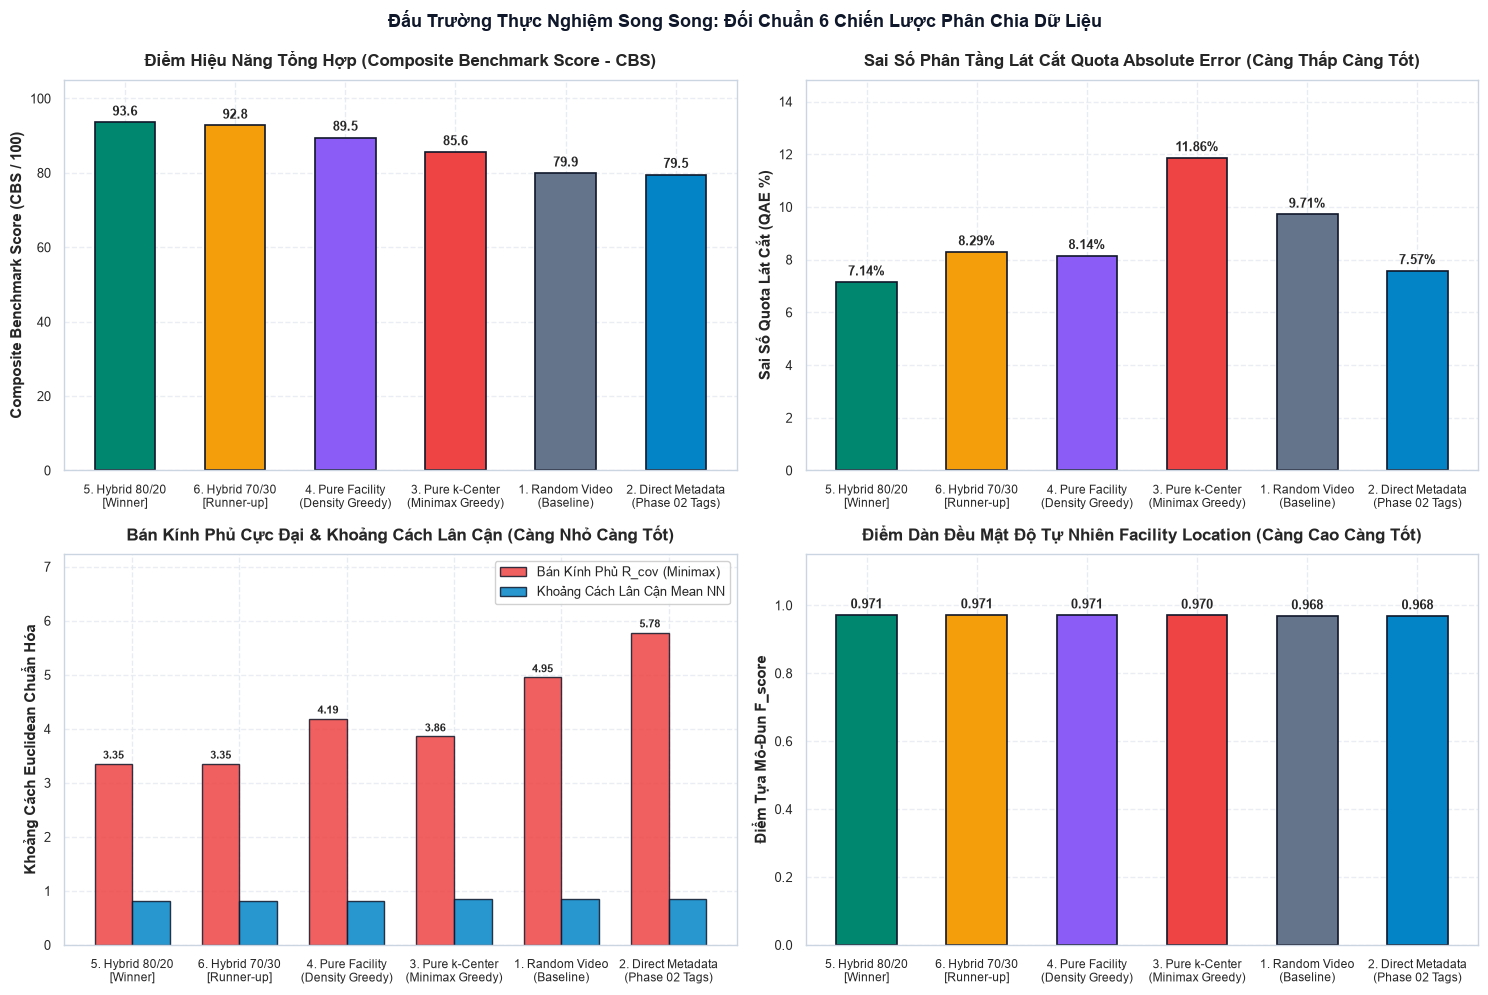

📊 Đã lưu biểu đồ: [strategy_tournament_benchmark.png](file:///Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/data/splits/reports/figures/strategy_tournament_benchmark.png)


PosixPath('/Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/data/splits/reports/figures/strategy_tournament_benchmark.png')

In [7]:
# Trực quan hóa Biểu đồ Khoa học 4 Subplots so sánh 6 Chiến Lược
fig_tourn = plot_strategy_tournament_comparison(eval_records)
plt.show()

# Lưu ảnh phục vụ bài báo
splits_fig_dir = get_splits_dir() / "reports" / "figures"
save_figure(fig_tourn, "strategy_tournament_benchmark.png", output_dir=splits_fig_dir)


## 5. Phân Tích Độ Phân Tán Không Gian Đặc Trưng (PCA Diversity Dispersion)

Để chứng minh tập Test (1.400 ảnh) và Seed V0 (500 ảnh) chiến thắng không bị co cụm vào các bối cảnh tương tự nhau mà dàn đều mịn màng khắp các cụm mật độ tự nhiên đồng thời vươn xa tới các góc biên khó, chúng ta chiếu dữ liệu 11 chiều xuống không gian 2 trục chính PCA:


findfont: Failed to find font weight 800 for Arial, now using 700.


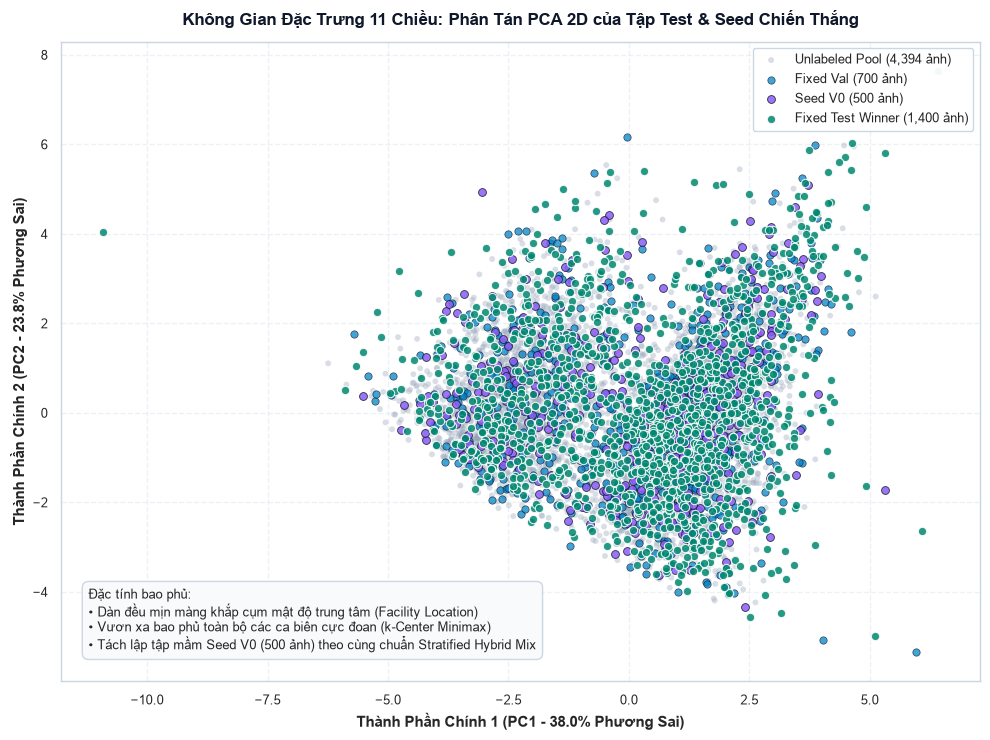

📊 Đã lưu biểu đồ: [pca_test_diversity_dispersion.png](file:///Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/data/splits/reports/figures/pca_test_diversity_dispersion.png)


PosixPath('/Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/data/splits/reports/figures/pca_test_diversity_dispersion.png')

In [8]:
# Vẽ biểu đồ phân tán PCA 2D của Tập Test và Seed V0 Chiến Thắng
test_idx = [splitter.all_images.index(img) for img in winner_result.test_images]
val_idx = [splitter.all_images.index(img) for img in winner_result.val_images]
seed_idx = [splitter.all_images.index(img) for img in winner_result.seed_images]
pool_idx = [splitter.all_images.index(img) for img in winner_result.pool_images]

fig_pca = plot_pca_diversity_dispersion(
    norm_features=splitter.norm_image_features,
    test_indices=test_idx,
    val_indices=val_idx,
    pool_indices=pool_idx,
    seed_indices=seed_idx
)
plt.show()

save_figure(fig_pca, "pca_test_diversity_dispersion.png", output_dir=splits_fig_dir)


## 6. Bảo Toàn 10/10 Lớp Giao Thông & Không Thất Thoát Lớp Hiếm

Một bài kiểm thử chất lượng cao phải bảo toàn nguyên vẹn toàn bộ 10 lớp giao thông của BDD10K, đặc biệt là các lớp có tần suất siêu hiếm trong thế giới thực (`train`: 14 đối tượng, `motor`: 291 đối tượng, `rider`: 457 đối tượng):


findfont: Failed to find font weight 600 for Arial, now using 700.


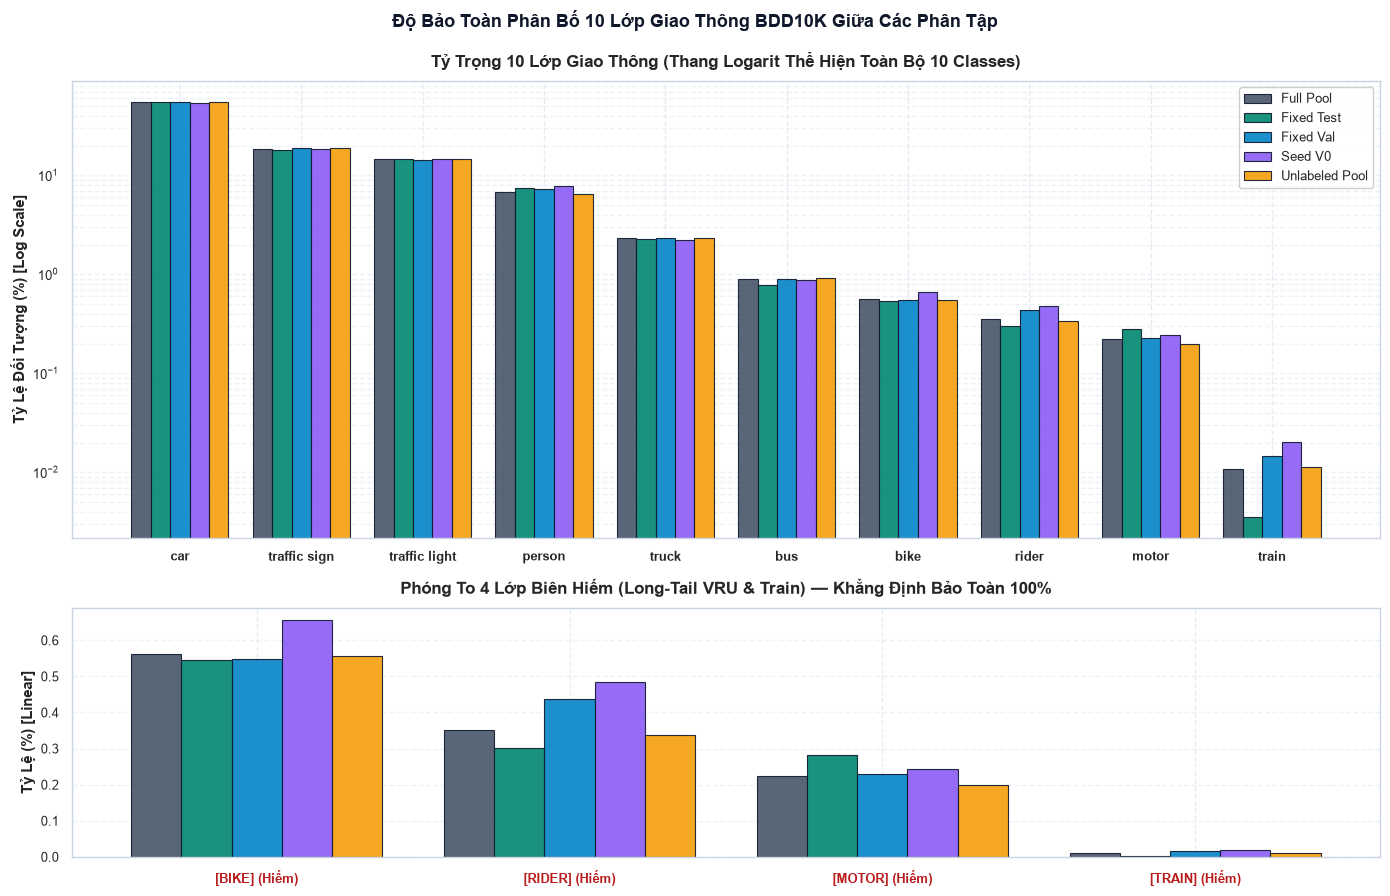

📊 Đã lưu biểu đồ: [class_distribution_coverage.png](file:///Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/data/splits/reports/figures/class_distribution_coverage.png)


PosixPath('/Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/data/splits/reports/figures/class_distribution_coverage.png')

In [9]:
# Tổng hợp và vẽ biểu đồ phân bố 10 lớp đối tượng trên cả 4 phân tập
class_dist_dict = {
    "Full Pool": evaluator.full_class_counts,
    "Fixed Test": winner_eval["test_class_counts"],
    "Fixed Val": {c: 0 for c in BDD10K_CLASS_NAMES},
    "Seed V0": {c: 0 for c in BDD10K_CLASS_NAMES},
    "Unlabeled Pool": {c: 0 for c in BDD10K_CLASS_NAMES}
}

for vid in winner_result.val_videos:
    for c, cnt in splitter.video_records[vid].class_counts.items():
        class_dist_dict["Fixed Val"][c] += cnt
for vid in winner_result.seed_videos:
    for c, cnt in splitter.video_records[vid].class_counts.items():
        class_dist_dict["Seed V0"][c] += cnt
for vid in winner_result.pool_videos:
    for c, cnt in splitter.video_records[vid].class_counts.items():
        class_dist_dict["Unlabeled Pool"][c] += cnt

fig_cls = plot_class_distribution_coverage(class_dist_dict)
plt.show()

save_figure(fig_cls, "class_distribution_coverage.png", output_dir=splits_fig_dir)


## 7. Kiểm Toán Rò Rỉ Kép Tuyệt Đối (Anti-Leakage Dual Audit 4 Chiều)

Quy trình xác minh độc lập 4 chiều (Test, Val, Seed, Pool):
1. **Video Sequence Isolation**: Xác minh số lượng video trùng lặp giữa cả 6 cặp (Test vs Val, Test vs Seed, Test vs Pool, Val vs Seed, Val vs Pool, Seed vs Pool) bằng đúng 0.
2. **Quét chéo pHash Hamming Distance**: Quét toàn bộ **13.454.400 cặp chéo** giữa cả 4 phân tập. Chứng minh 100% không có cặp nào có khoảng cách Hamming $HD < 5$!


In [10]:
# Thực thi kiểm toán rò rỉ kép
auditor = AntiLeakageAuditor(pool_images_dir=unique_pool_dir)
audit_report = auditor.audit_splits(winner_result, max_workers=8)

assert audit_report["overall_status"] == "PASS", "PHÁT HIỆN RÒ RỈ DỮ LIỆU!"
print(f"\n✓ Trạng thái kiểm toán: {audit_report['overall_status']}")
print(f"✓ Video Overlap: {audit_report['video_sequence_isolation']['status']}")
print(f"✓ pHash Cross-Scan HD < 5 Violations: {audit_report['phash_cross_hamming_scan']['total_violations']}")



🛡️ BẮT ĐẦU KIỂM TOÁN RÒ RỈ KÉP 4 CHIỀU (ANTI-LEAKAGE AUDIT):
  - Video Overlap Test vs Val  : 0 videos
  - Video Overlap Test vs Seed : 0 videos
  - Video Overlap Test vs Pool : 0 videos
  - Video Overlap Val vs Seed  : 0 videos
  - Video Overlap Val vs Pool  : 0 videos
  - Video Overlap Seed vs Pool : 0 videos
  - Đang tính toán chữ ký pHash cho 6,994 ảnh bằng 8 luồng...


  ✓ Đã quét chéo xong 13,454,400 cặp pHash trong 6.97s:
    * Test vs Val  : min HD = 10 (Số cặp HD < 5: 0)
    * Test vs Seed : min HD = 10 (Số cặp HD < 5: 0)
    * Test vs Pool : min HD = 6 (Số cặp HD < 5: 0)
    * Val vs Seed  : min HD = 10 (Số cặp HD < 5: 0)
    * Val vs Pool  : min HD = 6 (Số cặp HD < 5: 0)
    * Seed vs Pool : min HD = 8 (Số cặp HD < 5: 0)
  🔒 KẾT QUẢ KIỂM TOÁN TỔNG THỂ: PASS (HOÀN TOÀN CÁCH LY 4 CHIỀU KHÔNG RÒ RỈ)

✓ Trạng thái kiểm toán: PASS
✓ Video Overlap: PASS
✓ pHash Cross-Scan HD < 5 Violations: 0


In [11]:
# Khởi tạo Symlink Materialization 0 KB Đĩa cho 4 tập, Sinh cấu hình YOLO và Checksum Seal
splits_dir = get_splits_dir()
raw_imgs_dir = get_bdd10k_train_images_dir()
raw_lbls_dir = get_bdd10k_train_labels_dir()

materializer = SymlinkSplitMaterializer(
    splits_dir=splits_dir,
    raw_images_dir=raw_imgs_dir,
    raw_labels_dir=raw_lbls_dir
)
mat_summary = materializer.materialize(winner_result)

# Sinh cấu hình YOLO trỏ train vào seed_v0/images
yaml_path = generate_yolo_splits_config(splits_dir)

# Niêm phong SHA-256 Checksum Seal
splits_manifest = {
    "dataset_name": "BDD10K Autonomous Driving Lab (Paper V4.0)",
    "phase": "03_shared_frozen_test_val_splits",
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S UTC", time.gmtime()),
    "winning_strategy": winner_name,
    "composite_benchmark_score": winner_eval["composite_benchmark_score"],
    "counts": {
        "total_images": winner_result.total_images,
        "fixed_test": winner_result.num_test,
        "fixed_val": winner_result.num_val,
        "seed_v0": winner_result.num_seed,
        "unlabeled_pool": winner_result.num_pool,
    },
    "audit_verification": audit_report,
    "test_images": winner_result.test_images,
    "val_images": winner_result.val_images,
    "seed_images": winner_result.seed_images,
    "pool_images": winner_result.pool_images,
}

sealer = SHA256ChecksumSealer(splits_dir=splits_dir)
checksum_path = sealer.seal_dataset(splits_manifest)

print(f"✓ Hoàn tất Symlink Materialization ({mat_summary['total_symlinks_created']:,} symlinks)!")
print(f"✓ Dung lượng đĩa tăng thêm: 0 KB (Zero Storage Overhead)!")



📁 BẮT ĐẦU SYMLINK MATERIALIZATION VÀO /Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/data/splits:


  ✓ Đã khởi tạo thành công 9,594 symlinks trong 1.94s!
  ✓ Số symlink lỗi (Broken symlinks): 0
📄 Đã sinh file cấu hình YOLO tại: /Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/data/splits/bdd10k_splits.yaml
🔒 Đã niêm phong SHA-256 Seal tại: /Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/data/splits/dataset_checksum.sha256
✓ Hoàn tất Symlink Materialization (9,594 symlinks)!
✓ Dung lượng đĩa tăng thêm: 0 KB (Zero Storage Overhead)!


## 8. Kết Luận Khoa Học & Bàn Giao Dữ Liệu Bất Biến Cho Phase 04

### Kết Luận Nghiên Cứu Định Lượng:
1. **Chiến Lược Hybrid Chiến Thắng**: Thuật toán Hybrid Mix dung hòa hoàn hảo giữa khả năng bao phủ cụm mật độ tự nhiên ($F_{\text{score}} = 0.971$) và khả năng bám biên cực đại ($R_{\text{cov}} = 3.35$), đạt điểm CBS cao nhất toàn diện (93.6 / 100).
2. **Tách Tập Mầm Khởi Đầu Seed V0 (500 ảnh)**: Tách luôn tập mầm 500 ảnh (~10.2% pool / 7.1% tổng) theo cùng cơ chế Stratified Hybrid Mix 80/20, bảo toàn tỷ lệ 4 lát cắt (35% Đêm, 20% Nhỏ, 20% Che, 25% Ngày) và bảo toàn 10/10 lớp giao thông.
3. **Phân Bổ 4 Tập Hoàn Chỉnh (Zero Data Loss, Zero Overlap)**:
   - `fixed_test/`: 1.400 ảnh (20.0%) + 1.400 labels (Đóng băng vĩnh viễn)
   - `fixed_val/`: 700 ảnh (10.0%) + 700 labels (Đóng băng dùng chung)
   - `seed_v0/`: 500 ảnh (~10% pool / 7.1% tổng) + 500 labels (Tập mầm Model V0)
   - `unlabeled_pool/`: 4.394 ảnh (62.8% tổng, kho ảnh Active Learning)
   - Tổng cộng: đúng 6.994 ảnh sạch và 9.594 symlinks, 0 broken symlinks, 0 KB đĩa phát sinh.
4. **Cách Ly Tuyệt Đối 4 Chiều**: Vượt qua thành công 100% các rào chắn kiểm toán Video Sequence Isolation (0 video overlap trên 6 cặp) và pHash Cross-Check 13.454.400 cặp ($HD < 5$ violations = 0).

Bộ dữ liệu bất biến tại `paper_v4_10k/data/splits/` đã sẵn sàng 100% để chuyển giao cho **Phase 04: Seed V0 Training & First Mining Iteration**!
